In [ ]:
'''
- Matplotlib
- Seaborn
- Plotly

1. Analysis Chart
   a. Bar Chart
   b. Line Chart
   c. Columnn Chart
   d. Pie Chart
   e. Donut Chart
   f. Scatter Plot
   
2. Statistical Chart
    a. Histograms
    b. Box Plot
    c. Correlation Heatmaps
    d. Violin Plot
'''

In [48]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import plotly.express as px

In [2]:
employees = ['Bob', 'Arthur', 'Dutch', 'Bill', 'Xavier']
salary = [60000, 100000, 80000, 20000, 55000]
bonus = [40000, 60000, 45000, 10000, 25000]

## Line Plot

In [3]:
def formatDataPoints(val):
    if abs(val) > 1e9:
        return f'{val / 1e9:,.2f}B'
    elif abs(val) > 1e6:
        return f'{val / 1e6:,.2f}M'
    elif abs(val) > 1e3:
        return f'{val / 1e3:,.2f}K'
    else:
        return f'{val}'

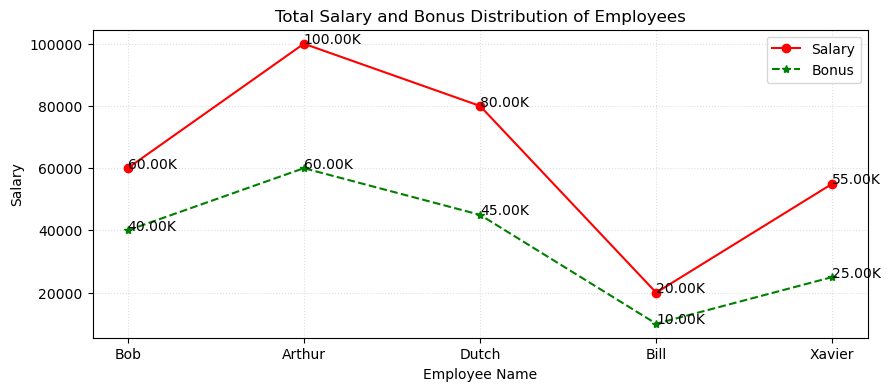

In [4]:
plt.figure(figsize=(10, 4)) # 800 x 400
plt.plot(employees, salary, color='red', marker='o', linestyle='solid', label='Salary')
plt.plot(employees, bonus, color='green', marker='*', linestyle='dashed', label='Bonus')
plt.xlabel('Employee Name')
plt.ylabel('Salary')
plt.title('Total Salary and Bonus Distribution of Employees')
plt.grid(linestyle='dotted', alpha=0.4)
plt.legend()
for idx, val in enumerate(salary):
    formatted_value = formatDataPoints(val)
    plt.text(idx, val, formatted_value)

for idx, val in enumerate(bonus):
    formatted_value = formatDataPoints(val)
    plt.text(idx, val, formatted_value)

plt.savefig('employee_salary_bonus.png')
plt.show()

## Bar Chart

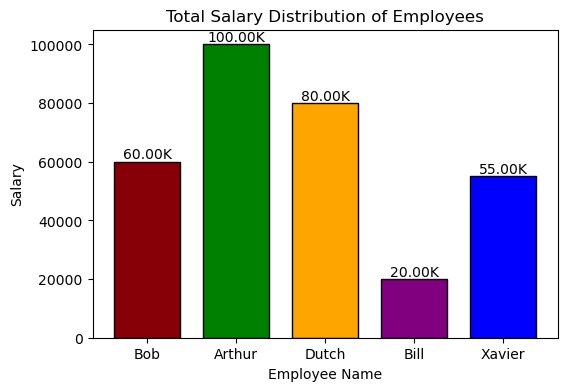

In [5]:
plt.figure(figsize=(6, 4))
colors = ['#870007', 'green', 'orange', 'purple', 'blue']
plt.bar(employees, salary, color=colors, width=0.75, edgecolor='black')
plt.xlabel('Employee Name')
plt.ylabel('Salary')
plt.title('Total Salary Distribution of Employees')

for idx, val in enumerate(salary):
    formatted_value = formatDataPoints(val)
    plt.text(idx, val, formatted_value, ha='center', va='bottom')

plt.show()

## Scatter Plot

In [6]:
temp = pd.read_csv('Dataset/temperature.csv')
temp.head()

,Temperature (°C),Humidity (%)
0,23.745401,57.186649
1,29.507143,66.765614
2,27.319939,64.034868
3,25.986585,60.921443
4,21.560186,49.099373


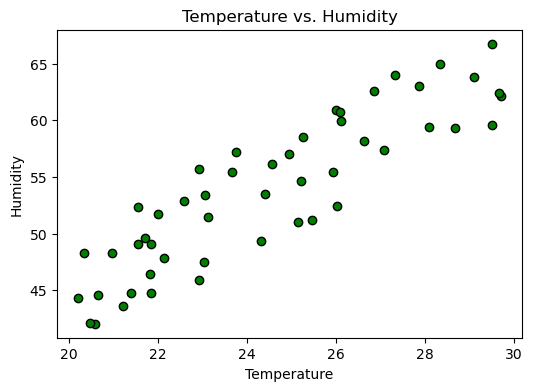

In [7]:
plt.figure(figsize=(6, 4))
plt.scatter(temp['Temperature (°C)'], temp['Humidity (%)'], color='green', edgecolor='black')
plt.xlabel('Temperature')
plt.ylabel('Humidity')
plt.title('Temperature vs. Humidity')
plt.show()

In [8]:
df = pd.read_csv('cleaned_hr.csv')
# df.head()

## Pie Chart

In [9]:
emp_performance = df.groupby('PerformanceScore')['EmpID'].count().reset_index().rename(
    columns = {'PerformanceScore': 'Performance Score', 'EmpID': 'Total Employees'}
)
# emp_performance

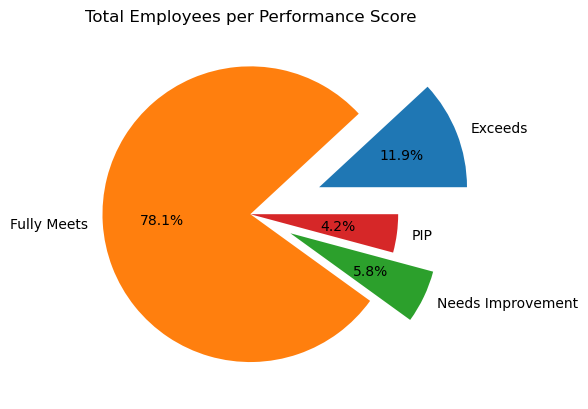

In [10]:
plt.pie(
    emp_performance['Total Employees'],
    labels=emp_performance['Performance Score'],
    autopct= '%1.1f%%',
    explode = (0.5, 0, 0.3, 0)
)
plt.title('Total Employees per Performance Score')
plt.show()

## Donut Chart

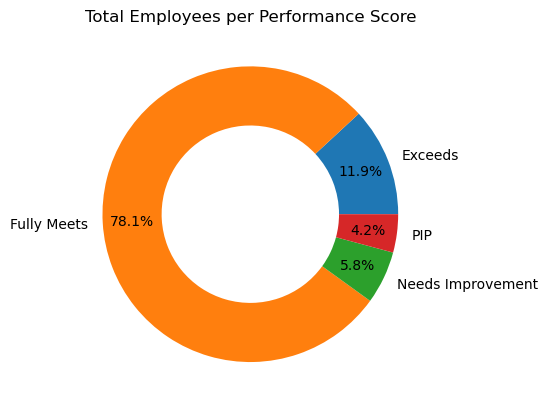

In [11]:
plt.pie(
    emp_performance['Total Employees'],
    labels=emp_performance['Performance Score'],
    autopct= '%1.1f%%',
    # width edge properties
    wedgeprops={'width':0.4},
    pctdistance=0.8
)
plt.title('Total Employees per Performance Score')
plt.show()

## Column Chart

In [11]:
emp_dep = df.groupby(['Department', 'Gender'])['EmpID'].count().reset_index().rename(
    columns = {'EmpID': 'Total Employees'}
)
# emp_dep

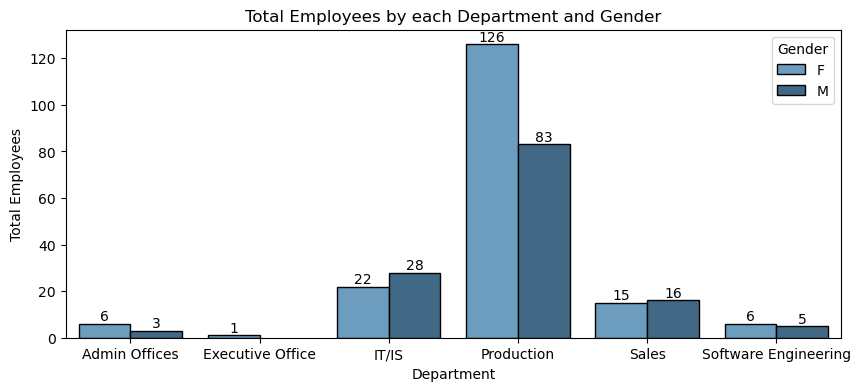

In [12]:
plt.figure(figsize=(10, 4))
ax = sns.barplot(data=emp_dep, x='Department', y='Total Employees', hue='Gender', 
            errorbar=None, palette='Blues_d', edgecolor='black')
plt.tick_params(axis='x', rotation=0)
plt.title('Total Employees by each Department and Gender')
for container in ax.containers:
    plt.bar_label(container)

plt.show()

# Statistical Chart

## Histogram

In [13]:
salary_df = df[df['Salary'].between(45000, 80000)]

In [14]:
skew = salary_df['Salary'].skew()
mean_salary = df['Salary'].mean()
median_salary = df['Salary'].median()

skew

np.float64(0.048420831309714654)

In [15]:
plt.figure(figsize=(6, 4))
plt.hist(df['Salary'], edgecolor='black')
plt.close()

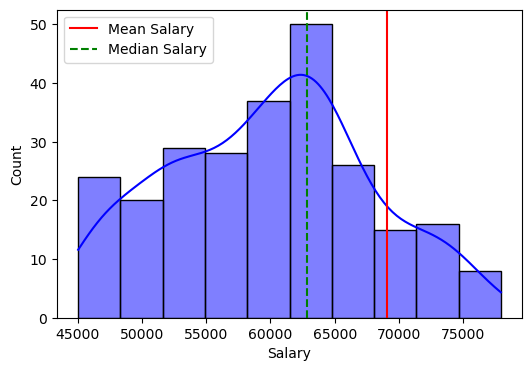

In [16]:
plt.figure(figsize=(6, 4))
sns.histplot(salary_df['Salary'], bins=10, kde=True, color='blue')
# axvline -> axis vertical line
plt.axvline(mean_salary, color='red', label='Mean Salary')
plt.axvline(median_salary, color='green', linestyle='dashed', label='Median Salary')
plt.legend()
plt.show()

## Box Plot

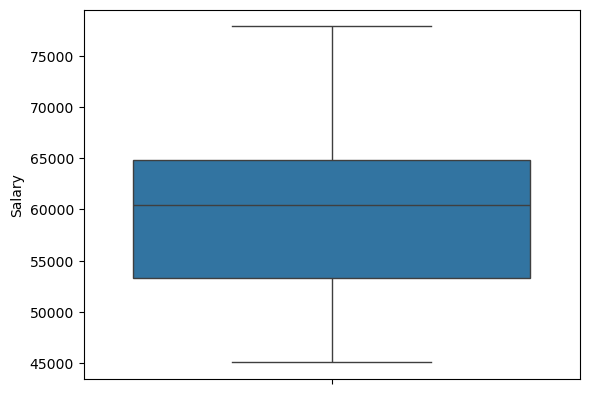

In [17]:
sns.boxplot(salary_df['Salary'])
plt.show()

<Axes: >

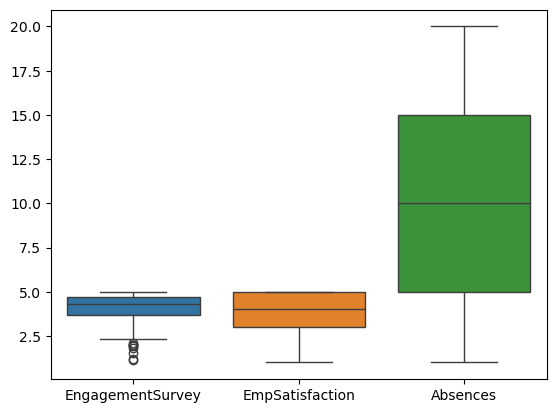

In [18]:
sns.boxplot(
    df[['EngagementSurvey', 'EmpSatisfaction', 'Absences']]
)

## SubPlots

In [19]:
dep_details = df.groupby('Department').agg(
    Total_Employees = ('EmpID', 'count'),
    Total_Salary = ('Salary', 'sum'),
    Total_Projects = ('SpecialProjectsCount', 'sum'),
    Total_Absences = ('Absences', 'sum')
).reset_index()
dep_details

,Department,Total_Employees,Total_Salary,Total_Projects,Total_Absences
0,Admin Offices,9,646127,33,78
1,Executive Office,1,250000,0,10
2,IT/IS,50,4853232,296,522
3,Production,209,12530291,4,2120
4,Sales,31,2140899,0,358
5,Software Engineering,11,1044884,46,96


In [20]:
def formatDataPoints(val):
    if abs(val) > 1e9:
        return f'{val / 1e9:,.2f}B'
    elif abs(val) > 1e6:
        return f'{val / 1e6:,.2f}M'
    elif abs(val) > 1e3:
        return f'{val / 1e3:,.2f}K'
    else:
        return f'{val}'

def text_data(ax, dataframe, col):
    for idx, val in enumerate(dataframe[col]):
        formatted_data = formatDataPoints(val)
        ax.text(idx, val, formatted_data, ha='center', va='bottom')

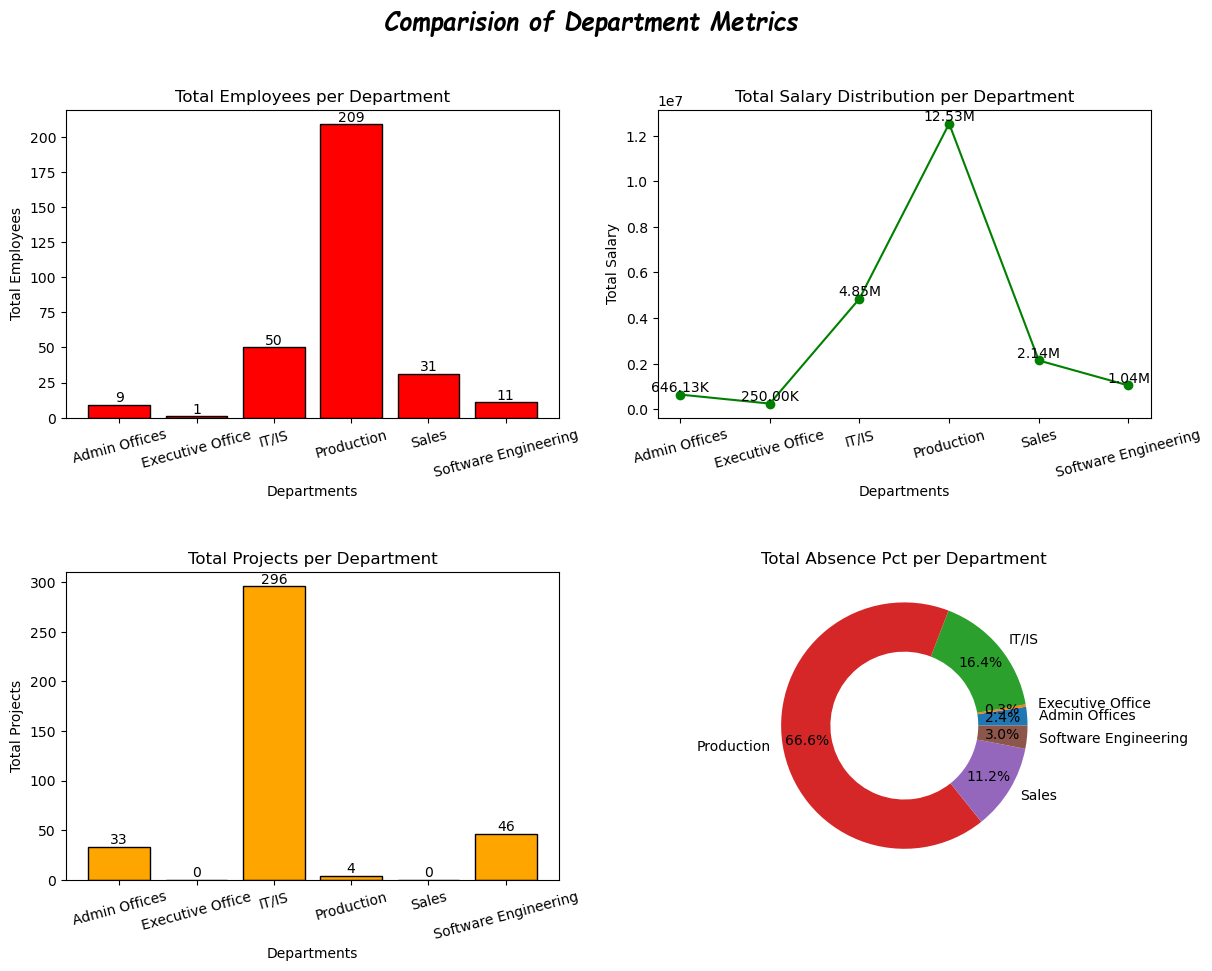

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plt.subplots_adjust(hspace=0.5)
plt.suptitle('Comparision of Department Metrics', fontsize='xx-large', fontweight='bold', fontstyle='italic',
            fontfamily='cursive')

ax1 = axes[0, 0]
ax1.bar(dep_details['Department'], dep_details['Total_Employees'], color='red', edgecolor='black')
ax1.set_xlabel('Departments')
ax1.set_ylabel('Total Employees')
ax1.set_title('Total Employees per Department')
ax1.tick_params(axis='x', rotation=15)
text_data(ax1, dep_details, 'Total_Employees')

ax2 = axes[0, 1]
ax2.plot(dep_details['Department'], dep_details['Total_Salary'], marker='o', color='green')
ax2.set_xlabel('Departments')
ax2.set_ylabel('Total Salary')
ax2.set_title('Total Salary Distribution per Department')
ax2.tick_params(axis='x', rotation=15)
text_data(ax2, dep_details, 'Total_Salary')

ax3 = axes[1, 0]
ax3.bar(dep_details['Department'], dep_details['Total_Projects'], color='orange', edgecolor='black')
ax3.set_xlabel('Departments')
ax3.set_ylabel('Total Projects')
ax3.set_title('Total Projects per Department')
ax3.tick_params(axis='x', rotation=15)
text_data(ax3, dep_details, 'Total_Projects')

ax4 = axes[1, 1]
ax4.pie(
    dep_details['Total_Absences'],
    labels=dep_details['Department'],
    autopct='%1.1f%%',
    wedgeprops={'width': 0.4},
    pctdistance=0.8
)
ax4.set_title('Total Absence Pct per Department')
plt.savefig('subplot.png')
plt.show()

## Correlation Heatmap

In [ ]:
'''
1. Pearson Correlation
2. Spearman Correlation
'''

In [30]:
data = df.select_dtypes(['int', 'float'])

In [31]:
data.columns

Index(['EmpID', 'MarriedID', 'MaritalStatusID', 'GenderID', 'EmpStatusID',
       'DeptID', 'PerfScoreID', 'FromDiversityJobFairID', 'Salary', 'Termd',
       'PositionID', 'Zip', 'ManagerID', 'EngagementSurvey', 'EmpSatisfaction',
       'SpecialProjectsCount', 'DaysLateLast30', 'Absences', 'Hire_Year',
       'Hire_Month', 'Hire_Day', 'sal_id', 'Salary_Label_id'],
      dtype='object')

In [32]:
data.drop(columns=['EmpID', 'MarriedID', 'MaritalStatusID', 'GenderID', 'EmpStatusID', 'FromDiversityJobFairID',
                  'ManagerID', 'Hire_Year', 'Hire_Month', 'Hire_Day', 'sal_id', 'Salary_Label_id', 'Termd'],
         inplace=True)

In [46]:
data_corr = data.corr(method='pearson')

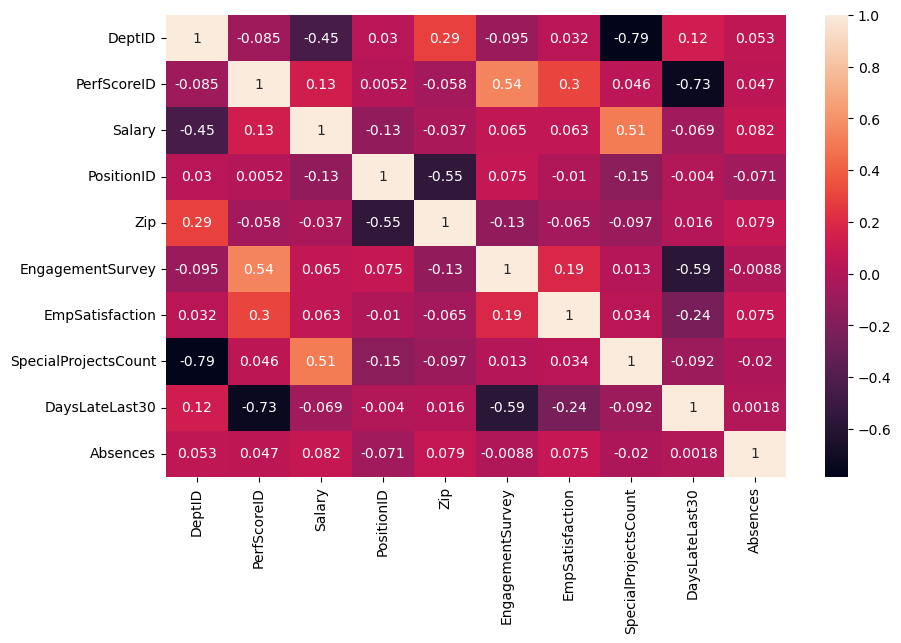

In [47]:
plt.figure(figsize=(10, 6))
sns.heatmap(data_corr, annot=True)
plt.show()

## Violin Plot

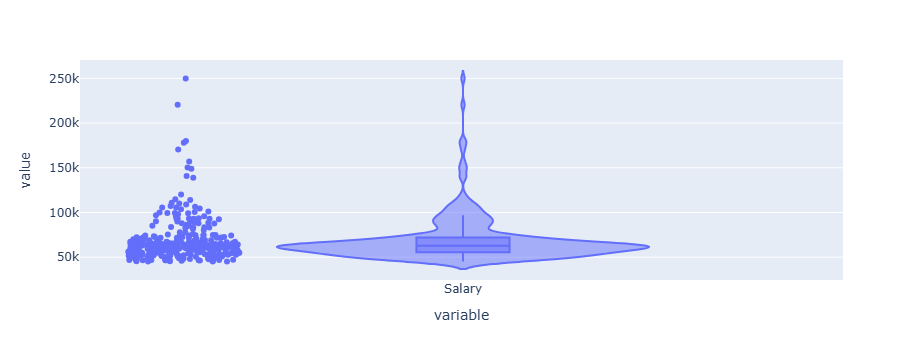

In [51]:
fig = px.violin(
    df,
    y=['Salary'],
    box=True,
    points='all'
)
fig.show()

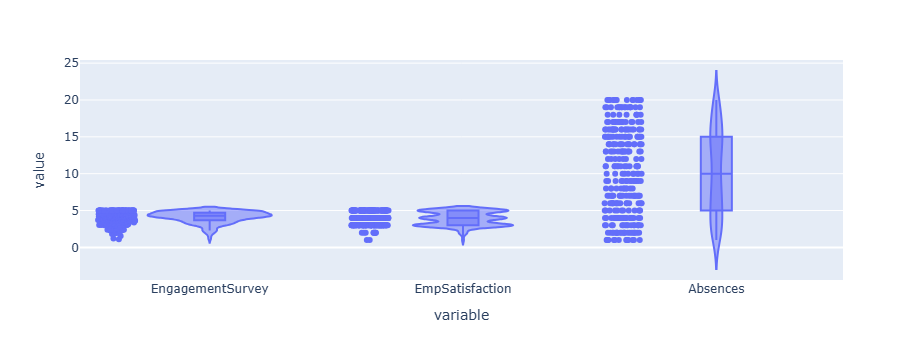

In [65]:
fig = px.violin(
    df,
    y = ['EngagementSurvey', 'EmpSatisfaction', 'Absences'],
    box=True,
    points='all'
)
fig.show()